# Stampi-Bombelli et al. (2024): packed bed versus monolith CO$_2$ breakthrough

Validation of RUPTURA against *On Comparing Packed Beds and Monoliths for CO$_2$
Capture from Air Through Experiments, Theory, and Modeling*, Ind. Eng. Chem. Res.
**63** (2024) 11637-11653, [doi:10.1021/acs.iecr.4c01392](https://doi.org/10.1021/acs.iecr.4c01392).

Eleven breakthrough experiments of Table 5 are reproduced: one at 400 ppm and
three at 5.6 % CO$_2$ on the 3 mm $\gamma$-alumina packed bed, and four at
400 ppm and three at 5.6 % on the $\gamma$-alumina wash-coated monolith.  Each of
the eleven is run twice, once per axial dispersion coefficient of Table 7, so the
directory tree is

```
dl_from_literature/<case>/       D_L from the Table 4 correlations
dl_from_stampibombelli/<case>/   D_L fitted by the authors, Table 7
```

**Model set-up.** `generate_runs.py` writes the twenty `simulation.json`
files (the packed bed at 400 ppm, whose breakthrough takes about two days, is
not run); `run.py -j 8` runs them eight at a time.  All of them use the
ROS34PW2 integrator at its default tolerances on 50 grid points, with a profile
every 12 s over 24 000 s, and the Danckwerts inlet, under which exactly the feed
enters the column.  (With CVODE, the steepest runs needed per-case settings; see
TODO B-ITG-11.)
Everything else is taken from the paper:

| quantity | source | value |
| --- | --- | --- |
| Toth isotherm of the pellets | Table 1 | $n_{s0}$ = 1.23 mol kg$^{-1}$, $b_0$ = 4839 kPa$^{-1}$, $t_0$ = 0.25, $\Delta H_0$ = 70 kJ mol$^{-1}$, $\chi$ = 0, $\alpha$ = 0.11 |
| monolith isotherm | Section 2.1 | $q^*_{\mathrm{mono}} = 0.035\,q^*_{\mathrm{pellet}}$ |
| packed bed | Table 2 | $L$ = 32.5 cm, $d$ = 3.37 cm, 187 g, $d_p$ = 3 mm, $\rho_p$ = 1044 kg m$^{-3}$ |
| monolith | Table 3 | $L$ = 13 cm, 12 $\times$ 12 square channels of 2 mm, 57.82 g, $\varepsilon$ = 0.68 |
| kinetics | Table 8 | $k_1$, $k_2$ per contactor and feed concentration, $\eta$ = 0.75 |
| axial dispersion | Table 7 | fitted and literature, one directory each |

**Mass transfer.** The packed bed uses the pseudo-first-order model, so the CO$_2$
component carries a single Toth site of capacity $q^*$ relaxing with $k = k_1$.
The monolith uses the dual-kinetic model of eqs 8-10, which needs *two* sites
that share one isotherm shape but relax at different rates,

$$q = q_1 + q_2, \qquad
  \frac{\partial q_1}{\partial t} = k_1(\eta q^* - q_1), \qquad
  \frac{\partial q_2}{\partial t} = k_2\bigl((1-\eta) q^* - q_2\bigr).$$

A RUPTURA `Component` has only one `MassTransferCoefficient`, which drives every
physisorption site, so the second site has to come from the `ChemisorptionSites`
list, whose entries each carry their own rate coefficient.  A site of
`"Type": "FirstOrder"` with a nested equilibrium `Isotherm` evaluates exactly
$\partial q/\partial t = k(q^* - q)$, so the mapping is

| paper | RUPTURA |
| --- | --- |
| surface amine sites, fraction $\eta$, rate $k_1$ | `PhysisorptionSites`: Toth with $q_{\mathrm{sat}} = \eta\,n_s$, relaxing with the component `MassTransferCoefficient` $= k_1$ |
| bulk amine-layer sites, fraction $1-\eta$, rate $k_2$ | `ChemisorptionSites`: `FirstOrder` with `rateCoefficient` $= k_2$ and a nested Toth of $q_{\mathrm{sat}} = (1-\eta)\,n_s$ |

The split is a *kinetic* one, not a physical physisorption/chemisorption
distinction: both sites use the same Toth parameters $b$ and $t$ and the same
heat of adsorption, only the saturation capacity is split $\eta : (1-\eta)$, so
the total equilibrium loading $\eta q^* + (1-\eta) q^* = q^*$ is unchanged and the
combined isotherm is identical to the packed-bed one scaled by 0.035.  RUPTURA's
label "chemisorption" here just means "the site family that carries its own rate
constant".  The packed bed sets $\eta = 1$ and therefore has no second site,
which is what the paper found as well: fitting the DK model to the packed-bed
curves collapsed it onto the PFO model.

**One deliberate departure from the paper.** Only the 5.6 % packed-bed runs
release enough heat to move the isotherm, so those three are non-isothermal and
all others are isothermal, consistent with the flat measured temperatures of
Figure 4a, c and d.  The paper reports $h_W$ = 10 and $h_L$ = 26 W m$^{-2}$
K$^{-1}$ but no wall dimensions, density or heat capacity, so the gas-wall
coefficient and the wall thickness were chosen to reproduce the measured
43 $^\circ$C peak of Figure 4b.

**Reference data.** `digitize_reference.py` recovers every experimental trace from
the 300 dpi rasters of Figures 4 and 5 by colour keying.  Line styles throughout:
solid for RUPTURA with the literature $D_L$, dotted for RUPTURA with the fitted
$D_L$ of Stampi-Bombelli et al., dashed with open markers for the digitised
experiment.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator

ROOT = Path.cwd()
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

plt.style.use("default")
plt.rcParams.update({
    "figure.figsize": (8, 6),
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 14,
    "legend.fontsize": 14,
    "axes.titlesize": 16,
    "figure.titlesize": 16,
    "lines.linewidth": 2.0,
    "axes.grid": False,
    "axes.labelpad": 6.0,
})

MARKERS = ("o", "s", "^", "D")

# The same eleven experiments are simulated twice, once per axial dispersion
# coefficient of Table 7, into one directory each.  Both are drawn in the colour
# of the run, the literature variant with a dotted line so the two are separable
# in black and white.  The fitted D_L of the authors is the base model (with the
# Danckwerts inlet it reproduces their fits; see the notes below).
MODELS = {
    "dl_from_stampibombelli": dict(
        label=r"RUPTURA, $D_L$ Stampi-Bombelli", linestyle="-", width=2.0),
    "dl_from_literature": dict(
        label=r"RUPTURA, $D_L$ literature", linestyle=":", width=2.0),
}
BASE_MODEL = "dl_from_stampibombelli"

# `dl_from` argument of the plotting functions.  A given dispersion coefficient
# always keeps its own line style, whether it is drawn on its own or next to the
# other one, so a solid curve is the fitted D_L in every figure.
DL_FROM = {
    "literature": ("dl_from_literature",),
    "stampi_bombelli": ("dl_from_stampibombelli",),
    "both": ("dl_from_literature", "dl_from_stampibombelli"),
}


def selected_models(dl_from):
    '''Model directories for one `dl_from` choice.'''
    if dl_from not in DL_FROM:
        raise ValueError(f"dl_from must be one of {sorted(DL_FROM)}, not {dl_from!r}")
    return DL_FROM[dl_from]

# One panel per contactor/feed-concentration pair.  `colour` is the matplotlib
# default colour of the panel; the individual velocities are drawn as darker and
# lighter variants of it, darkest at the highest velocity, exactly as the paper
# uses darker and lighter shades of one hue per panel.
PANELS = {
    "packed_bed_400ppm": dict(
        colour="C0", contactor="packed bed", feed=r"$y_{\mathrm{in}}$ = 400 ppm",
        thermocouple="middle",
        cases=["packed_bed_400ppm_2mmol"]),
    "packed_bed_5.6pct": dict(
        colour="C1", contactor="packed bed", feed=r"$y_{\mathrm{in}}$ = 5.6%",
        thermocouple="middle",
        cases=["packed_bed_5.6pct_2mmol", "packed_bed_5.6pct_1mmol",
               "packed_bed_5.6pct_0p5mmol"]),
    "monolith_400ppm": dict(
        colour="C2", contactor="monolith", feed=r"$y_{\mathrm{in}}$ = 400 ppm",
        thermocouple="end",
        cases=["monolith_400ppm_3mmol", "monolith_400ppm_2mmol",
               "monolith_400ppm_1mmol", "monolith_400ppm_0p18mmol"]),
    "monolith_5.6pct": dict(
        colour="C3", contactor="monolith", feed=r"$y_{\mathrm{in}}$ = 5.6%",
        thermocouple="end",
        cases=["monolith_5.6pct_0p18mmol", "monolith_5.6pct_0p06mmol",
               "monolith_5.6pct_0p02mmol"]),
}

# Feed flow rate and interstitial velocity of every run (Table 5 of the paper,
# velocities recomputed from the flow rate and the open cross-section).
FLOW_MMOL_S = {
    "packed_bed_400ppm_2mmol": 2.00, "packed_bed_5.6pct_2mmol": 2.00,
    "packed_bed_5.6pct_1mmol": 1.00, "packed_bed_5.6pct_0p5mmol": 0.50,
    "monolith_400ppm_3mmol": 3.00, "monolith_400ppm_2mmol": 2.00,
    "monolith_400ppm_1mmol": 1.00, "monolith_400ppm_0p18mmol": 0.18,
    "monolith_5.6pct_0p18mmol": 0.18, "monolith_5.6pct_0p06mmol": 0.06,
    "monolith_5.6pct_0p02mmol": 0.02,
}
COLUMN_LENGTH = {"packed_bed": 0.325, "monolith": 0.13}
SORBENT_MASS = {"packed_bed": 0.187, "monolith": 0.05782}


def contactor_of(case):
    return "packed_bed" if case.startswith("packed_bed") else "monolith"


def shade(colour, factor):
    '''Darker (factor < 1) or lighter (factor > 1) variant of a base colour.'''
    return tuple(np.clip(np.asarray(to_rgb(colour)) * factor, 0.0, 1.0))


def panel_styles(key):
    '''Return {case: (colour, marker)} for one panel, darkest at highest flow.'''
    cases = PANELS[key]["cases"]
    factors = [1.0] if len(cases) == 1 else np.linspace(0.65, 1.35, len(cases))
    return {case: (shade(PANELS[key]["colour"], factor), MARKERS[index])
            for index, (case, factor) in enumerate(zip(cases, factors))}


def flow_label(case):
    return rf"{FLOW_MMOL_S[case]:g} mmol s$^{{-1}}$"


def format_axis_ticks(axis, which):
    '''Plain decimal ticks, switching to LaTeX scientific notation ($4 \\times
    10^{-4}$, $10^{6}$) for any tick that needs 6 or more digits to write out
    in full, so the axis never needs a separate multiplier written above it.
    Scientific labels are wider than plain ones, so the tick count is also
    thinned out whenever they are used, to keep neighbouring labels from
    overlapping.
    '''
    axis_obj = axis.yaxis if which == "y" else axis.xaxis

    def digit_count(value, decimals):
        return sum(character.isdigit() for character in f"{value:.{decimals}f}")

    ticks = axis_obj.get_majorticklocs()
    step = abs(ticks[1] - ticks[0]) if len(ticks) > 1 else abs(ticks[0])
    decimals = max(0, -int(np.floor(np.log10(step)))) if step > 0 else 0
    needs_scientific = any(value != 0 and digit_count(value, decimals) >= 6
                           for value in ticks)
    if needs_scientific:
        axis_obj.set_major_locator(MaxNLocator(nbins=5, min_n_ticks=3))
        ticks = axis_obj.get_majorticklocs()
        step = abs(ticks[1] - ticks[0]) if len(ticks) > 1 else abs(ticks[0])
        decimals = max(0, -int(np.floor(np.log10(step)))) if step > 0 else 0

    def format_tick(value, _pos):
        if value == 0:
            return "0"
        plain = f"{value:.{decimals}f}"
        if digit_count(value, decimals) < 6:
            return plain
        exponent = int(np.floor(np.log10(abs(value))))
        mantissa = value / 10.0**exponent
        if abs(mantissa - round(mantissa)) < 1.0e-6:
            mantissa = int(round(mantissa))
        if mantissa == 1:
            return rf"$10^{{{exponent}}}$"
        return rf"${mantissa:g} \times 10^{{{exponent}}}$"

    axis_obj.set_major_formatter(FuncFormatter(format_tick))

In [2]:
# ---------------------------------------------------------------- data readers
def available(case, model):
    '''True when that run has been executed, i.e. its output files exist.

    `run_all.sh` fills in whatever is missing; the figures below simply leave out
    a run that has not been done yet.
    '''
    return (ROOT / model / case / "component_1_CO2.data").is_file()


def read_ruptura(case, model=BASE_MODEL):
    '''Outlet time in s and outlet mole fraction normalised by the feed.'''
    data = np.loadtxt(ROOT / model / case / "component_1_CO2.data", comments="#")
    position = data[:, 2]
    outlet = position > position.max() - 1.0e-9
    time_s = data[outlet, 1] * 60.0
    fraction = data[outlet, 12]
    order = np.argsort(time_s)
    return time_s[order], np.clip(fraction[order], 0.0, None)


def read_ruptura_temperature(case, thermocouple, model=BASE_MODEL):
    '''Solid temperature in kelvin at the thermocouple position.

    The packed-bed thermocouple sits at z = 0.5 L and the monolith one at z = L
    (Section 2.2 of the paper).
    '''
    data = np.loadtxt(ROOT / model / case / "column.data", comments="#")
    position = data[:, 2]
    nodes = np.unique(position)
    target = nodes.max() * (0.5 if thermocouple == "middle" else 1.0)
    node = nodes[np.argmin(np.abs(nodes - target))]
    selected = position == node
    time_s = data[selected, 1] * 60.0
    temperature = data[selected, 7]
    order = np.argsort(time_s)
    return time_s[order], temperature[order]


def read_ruptura_loading(case, model=BASE_MODEL):
    '''Time in s and the axial mean of q_phys + q_chem in mol/kg.'''
    data = np.loadtxt(ROOT / model / case / "component_1_CO2.data", comments="#")
    time_s = data[:, 1] * 60.0
    position = data[:, 2]
    loading = data[:, 6] + (data[:, 8] if data.shape[1] > 8 else 0.0)
    times, starts = np.unique(time_s, return_index=True)
    average = np.empty_like(times)
    for index, start in enumerate(starts):
        stop = starts[index + 1] if index + 1 < starts.size else data.shape[0]
        order = np.argsort(position[start:stop])
        z = position[start:stop][order]
        q = loading[start:stop][order]
        average[index] = np.trapezoid(q, z) / (z[-1] - z[0])
    return times, average


def read_reference(prefix, case):
    '''One digitised trace, or (None, None) when the trace is fully occluded.'''
    path = ROOT / "reference_digitized" / f"{prefix}_{case}.csv"
    if not path.is_file():
        return None, None
    data = np.loadtxt(path, delimiter=",", skiprows=1, ndmin=2)
    return data[:, 0], data[:, 1]


def crossing(time_s, fraction, level):
    '''Time at which a monotonised breakthrough curve first reaches `level`.'''
    rising = np.maximum.accumulate(fraction)
    if rising[-1] < level:
        return np.nan
    return float(np.interp(level, rising, time_s))


def marker_stride(count, maximum=32):
    '''Stride that keeps at most `maximum` markers on a digitised trace.'''
    return max(1, int(np.ceil(count / maximum)))


def plot_reference(axis, x, y, colour, marker, **kwargs):
    '''Digitised paper data: dashed line, open markers, at most 32 of them.'''
    return axis.plot(x, y, linestyle="--", linewidth=1.4, color=colour,
                     marker=marker, markevery=marker_stride(len(x)),
                     markerfacecolor="none", markeredgecolor=colour,
                     markersize=6, markeredgewidth=1.2, **kwargs)[0]


def flow_legend(axis, styles, **kwargs):
    '''Legend of the per-velocity colours and markers.'''
    handles = [Line2D([0], [0], color=colour, linestyle="-", linewidth=2.0,
                      marker=marker, markerfacecolor="none",
                      markeredgecolor=colour, markersize=6, label=flow_label(case))
               for case, (colour, marker) in styles.items()]
    return axis.legend(handles=handles, **kwargs)


def line_style_legend(axis, dl_from="both", **kwargs):
    '''Key for the RUPTURA line styles shown and the open-marker paper data.'''
    handles = [Line2D([0], [0], color="0.35", linewidth=MODELS[model]["width"],
                      linestyle=MODELS[model]["linestyle"], label=MODELS[model]["label"])
               for model in selected_models(dl_from)]
    handles.append(
        Line2D([0], [0], color="0.35", linestyle="--", linewidth=1.4, marker="o",
               markerfacecolor="none", markeredgecolor="0.35", label="experiment"))
    return axis.legend(handles=handles, **kwargs)

## Figure 4 - breakthrough curves and column temperatures

Each panel shows the CO$_2$ mole fraction at the column exit (top) and the
temperature at the thermocouple position (bottom), for one contactor and one feed
concentration.

In [3]:
def figure_4_panel(key, time_limit_s, mole_fraction_limit, filename,
                   dl_from="both", temperature_limit=(293.15, 318.15),
                   legend_location="lower right", legend_columns=1):
    '''dl_from selects the dispersion coefficient: "literature",
    "stampi_bombelli" or "both".'''
    panel = PANELS[key]
    styles = panel_styles(key)
    models = selected_models(dl_from)

    figure, (top, bottom) = plt.subplots(
        2, 1, figsize=(8, 6), sharex=True,
        gridspec_kw={"height_ratios": [2.0, 1.0], "hspace": 0.12})

    for case, (colour, marker) in styles.items():
        feed = 400.0e-6 if "400ppm" in case else 0.056
        for model in models:
            if not available(case, model):
                continue
            style = MODELS[model]
            time_s, fraction = read_ruptura(case, model)
            top.plot(time_s, fraction * feed, color=colour,
                     linestyle=style["linestyle"], linewidth=style["width"])

            temperature_time, temperature = read_ruptura_temperature(
                case, panel["thermocouple"], model)
            bottom.plot(temperature_time, temperature, color=colour,
                        linestyle=style["linestyle"], linewidth=style["width"])

        reference_time, reference_fraction = read_reference("figure4", case)
        if reference_time is not None:
            plot_reference(top, reference_time, reference_fraction * feed,
                           colour, marker)

        reference_time, reference_temperature = read_reference(
            "figure4_temperature", case)
        if reference_time is not None:
            plot_reference(bottom, reference_time, reference_temperature + 273.15,
                           colour, marker)

    top.set(xlim=(0.0, time_limit_s), ylim=(0.0, mole_fraction_limit),
            ylabel=r"CO$_2$ mole fraction, $y$ / [-]",
            title=f"{panel['contactor']}, {panel['feed']}")
    format_axis_ticks(top, "y")
    top.tick_params(labelbottom=False)
    flow_legend(top, styles, loc=legend_location, ncol=legend_columns)

    bottom.set(xlim=(0.0, time_limit_s), ylim=temperature_limit,
               xlabel=r"Time, $t$ / s",
               ylabel=r"$T_{\mathrm{col}}$ / K")
    format_axis_ticks(bottom, "x")
    line_style_legend(bottom, dl_from, loc="upper right", ncol=2)

    figure.savefig(FIGURES / f"{filename}.pdf", bbox_inches="tight")
    figure.savefig(FIGURES / f"{filename}.png", bbox_inches="tight")
    plt.show()

### Figure 4a - packed bed, 400 ppm

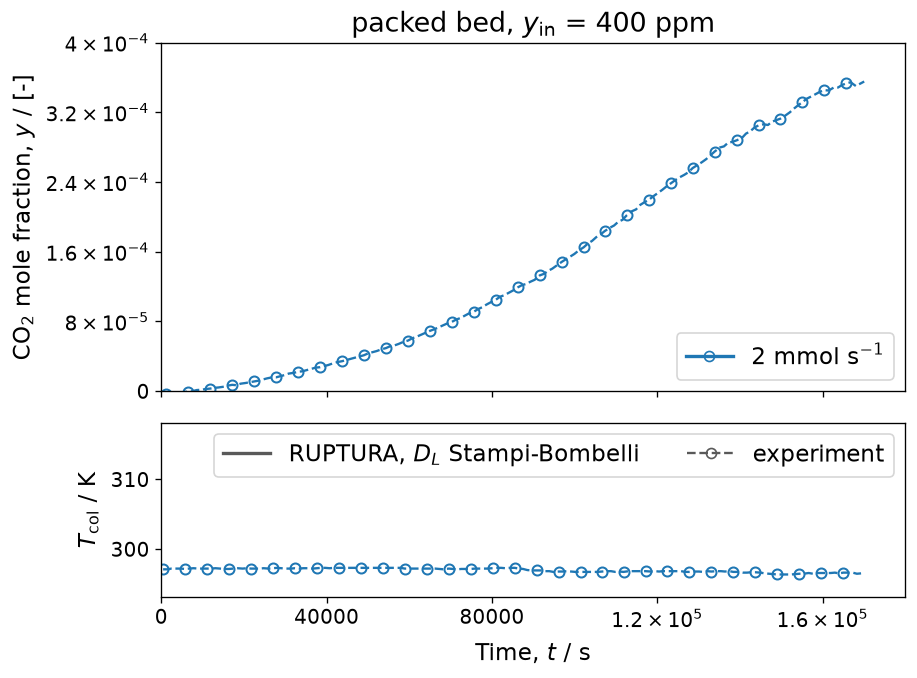

In [4]:
figure_4_panel("packed_bed_400ppm", time_limit_s=180000.0,
               mole_fraction_limit=4.0e-4, filename="figure_4a",
               dl_from="stampi_bombelli")

### Figure 4b - packed bed, 5.6 %

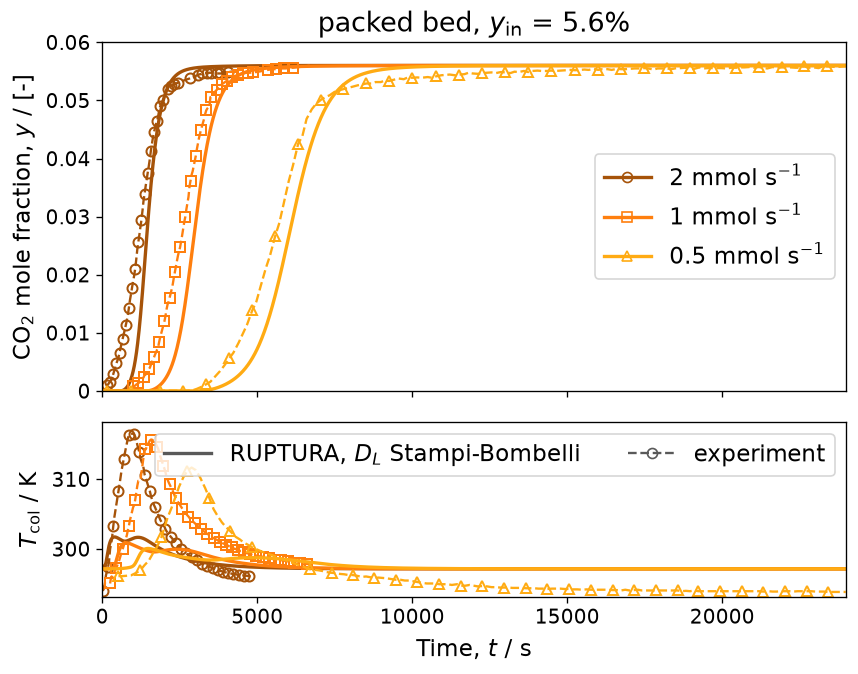

In [5]:
figure_4_panel("packed_bed_5.6pct", time_limit_s=24000.0,
               mole_fraction_limit=6.0e-2, filename="figure_4b",
               dl_from="stampi_bombelli", legend_location="center right")

### Figure 4c - monolith, 400 ppm

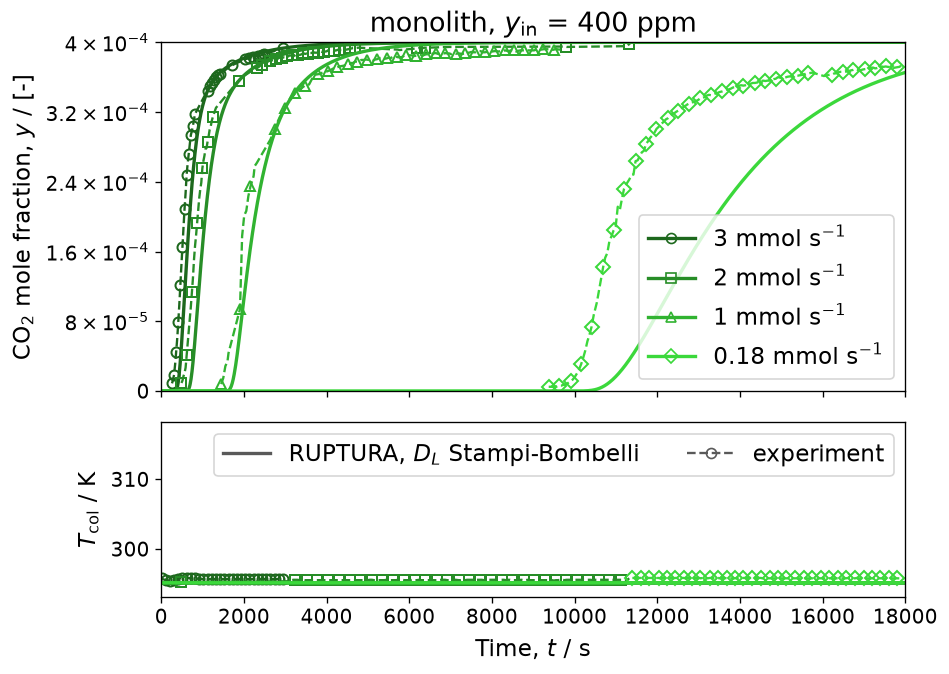

In [6]:
figure_4_panel("monolith_400ppm", time_limit_s=18000.0,
               mole_fraction_limit=4.0e-4, filename="figure_4c",
               dl_from="stampi_bombelli", legend_location="lower right", legend_columns=1)

### Figure 4d - monolith, 5.6 %

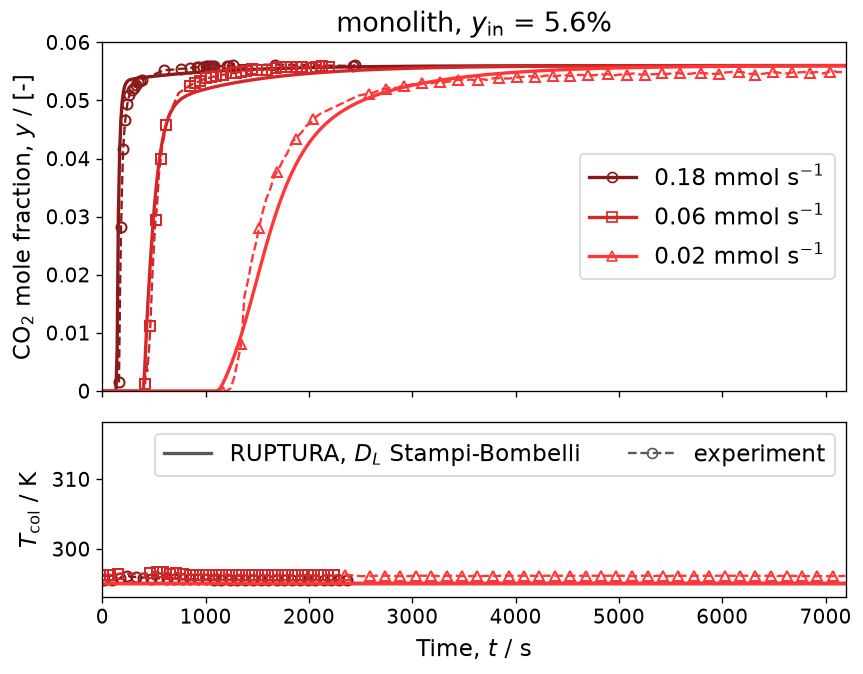

In [7]:
figure_4_panel("monolith_5.6pct", time_limit_s=7200.0,
               mole_fraction_limit=6.0e-2, filename="figure_4d",
               dl_from="stampi_bombelli", legend_location="center right")

## Figure 5 - effect of the feed velocity on the steepness of the front

The breakthrough curves of one contactor and one feed concentration, shifted so
that the origin sits at $t_{50}$ (panels a-c) or at $\tau_{50}$ in the
dimensionless time $\tau = tu/L$ (panels d-f).  Plotted this way, a front whose
width is set by axial dispersion collapses onto a single curve in $\tau$, while a
front whose width is set by mass transfer does not.

In [8]:
def figure_5_panel(key, kind, axis_limit, filename, title=None, dl_from="both",
                   legend_location="lower right", legend_columns=1):
    '''kind = "time" for panels a-c (seconds) or "tau" for panels d-f.

    dl_from selects the dispersion coefficient: "literature", "stampi_bombelli"
    or "both".
    '''
    panel = PANELS[key]
    styles = panel_styles(key)
    models = selected_models(dl_from)

    figure, axis = plt.subplots(figsize=(8, 6))
    length = COLUMN_LENGTH[contactor_of(panel["cases"][0])]

    for case, (colour, marker) in styles.items():
        for model in models:
            if not available(case, model):
                continue
            style = MODELS[model]
            time_s, fraction = read_ruptura(case, model)
            half = crossing(time_s, fraction, 0.5)
            if kind == "time":
                abscissa = time_s - half
            else:
                velocity = np.loadtxt(ROOT / model / case / "column.data",
                                      comments="#")[0, 3]
                abscissa = (time_s - half) * velocity / length
            axis.plot(abscissa, fraction, color=colour,
                      linestyle=style["linestyle"], linewidth=style["width"])

        reference_x, reference_y = read_reference(f"figure5_{kind}", case)
        if reference_x is not None:
            # figure5_time traces are digitised in minutes; figure5_tau ones are
            # already the dimensionless shifted time and need no scaling.
            scaled_x = reference_x * 60.0 if kind == "time" else reference_x
            plot_reference(axis, scaled_x, reference_y, colour, marker)

    label = (r"Shifted time, $t - t_{50}$ / s" if kind == "time"
             else r"Shifted dimensionless time, $\tau - \tau_{50}$ / [-]")
    axis.set(xlim=(-axis_limit, axis_limit), ylim=(-0.2, 1.05), xlabel=label,
             ylabel=r"Normalised outlet concentration, $c/c_{\mathrm{in}}$ / [-]",
             title=title or f"{panel['contactor']}, {panel['feed']}")
    format_axis_ticks(axis, "x")
    format_axis_ticks(axis, "y")
    first = flow_legend(axis, styles, loc=legend_location, ncol=legend_columns)
    axis.add_artist(first)
    line_style_legend(axis, dl_from, loc="upper left")

    figure.savefig(FIGURES / f"{filename}.pdf", bbox_inches="tight")
    figure.savefig(FIGURES / f"{filename}.png", bbox_inches="tight")
    plt.show()

### Figure 5a - packed bed, 5.6 %, shifted by $t_{50}$

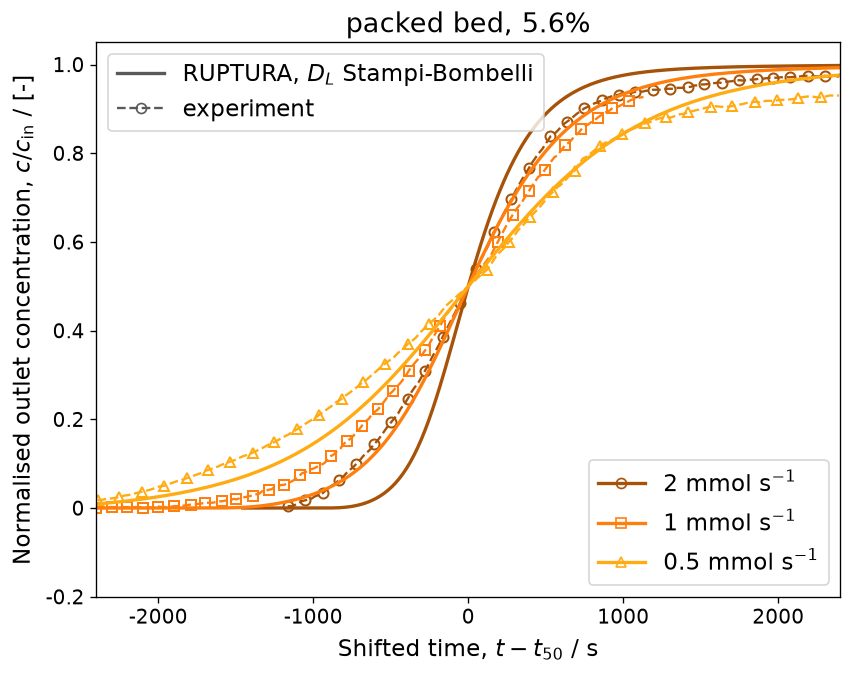

In [9]:
figure_5_panel("packed_bed_5.6pct", "time", axis_limit=2400.0, filename="figure_5a",
               title="packed bed, 5.6%", dl_from="stampi_bombelli",
               legend_location="lower right")

### Figure 5b - monolith, 5.6 %, shifted by $t_{50}$

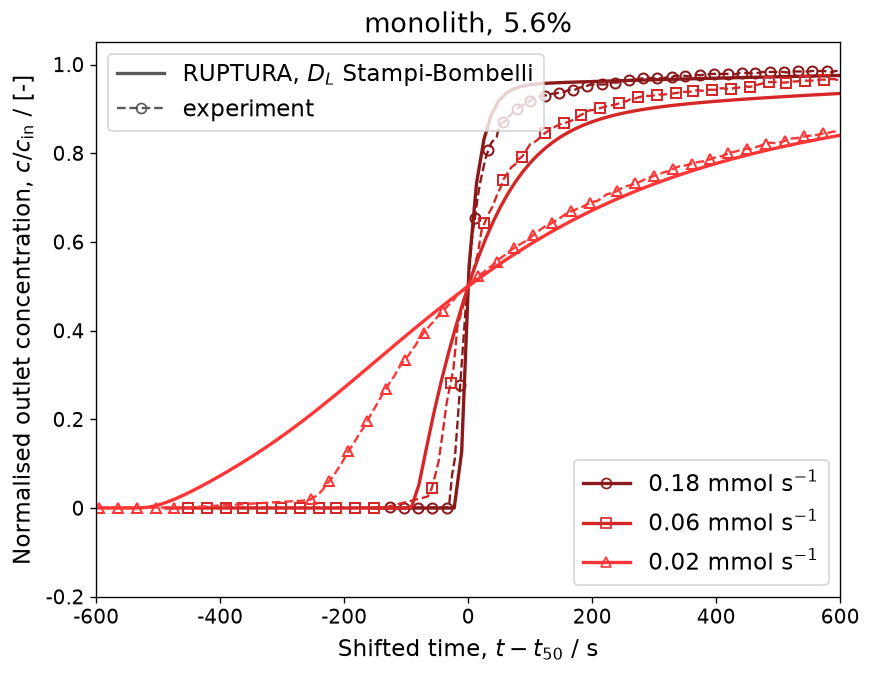

In [10]:
figure_5_panel("monolith_5.6pct", "time", axis_limit=600.0, filename="figure_5b",
               title="monolith, 5.6%", dl_from="stampi_bombelli",
               legend_location="lower right")

### Figure 5c - monolith, 400 ppm, shifted by $t_{50}$

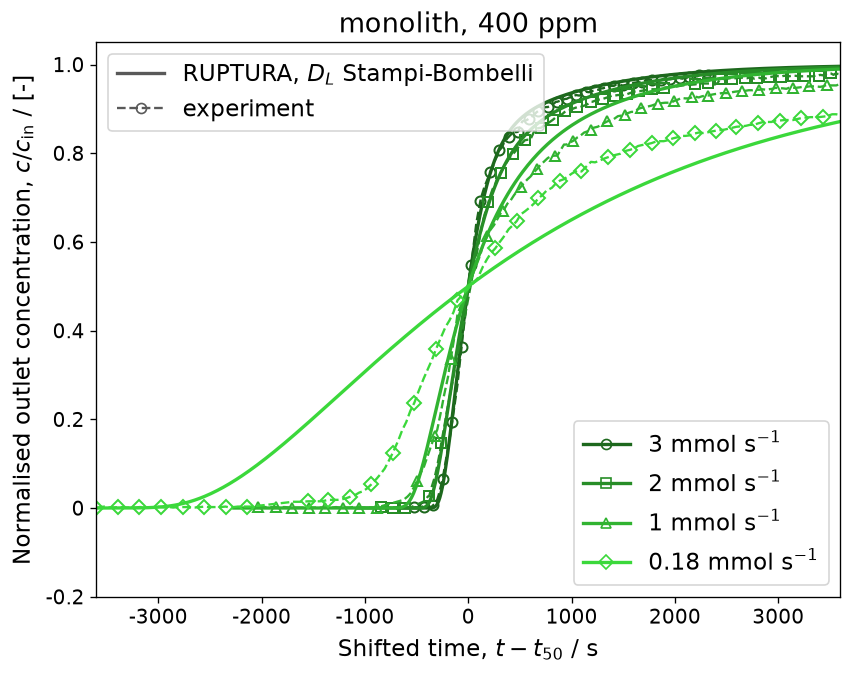

In [11]:
figure_5_panel("monolith_400ppm", "time", axis_limit=3600.0, filename="figure_5c",
               title="monolith, 400 ppm", dl_from="stampi_bombelli",
               legend_location="lower right", legend_columns=1)

### Figure 5d - packed bed, 5.6 %, shifted by $\tau_{50}$

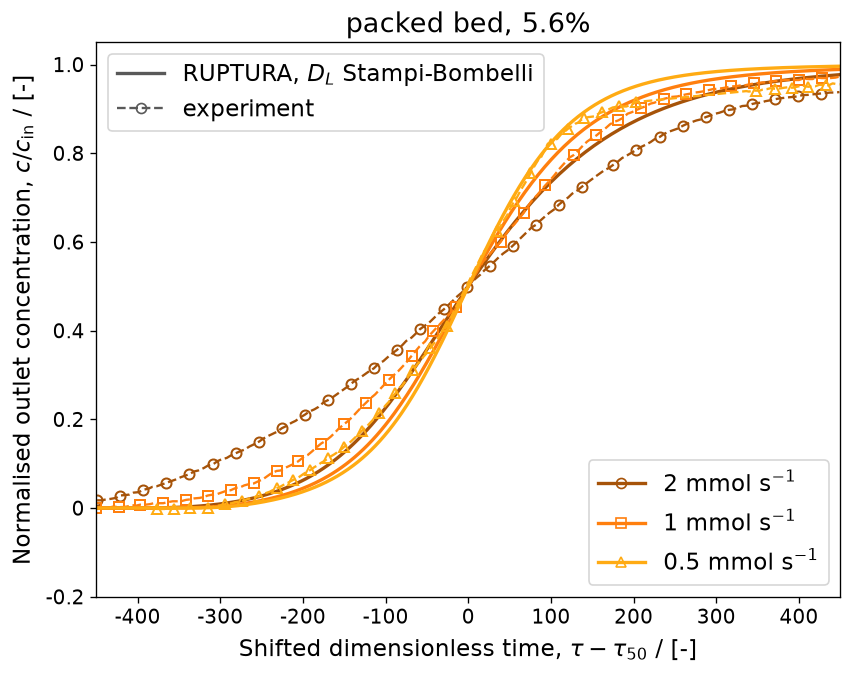

In [12]:
figure_5_panel("packed_bed_5.6pct", "tau", axis_limit=450.0, filename="figure_5d",
               title="packed bed, 5.6%", dl_from="stampi_bombelli",
               legend_location="lower right")

### Figure 5e - monolith, 5.6 %, shifted by $\tau_{50}$

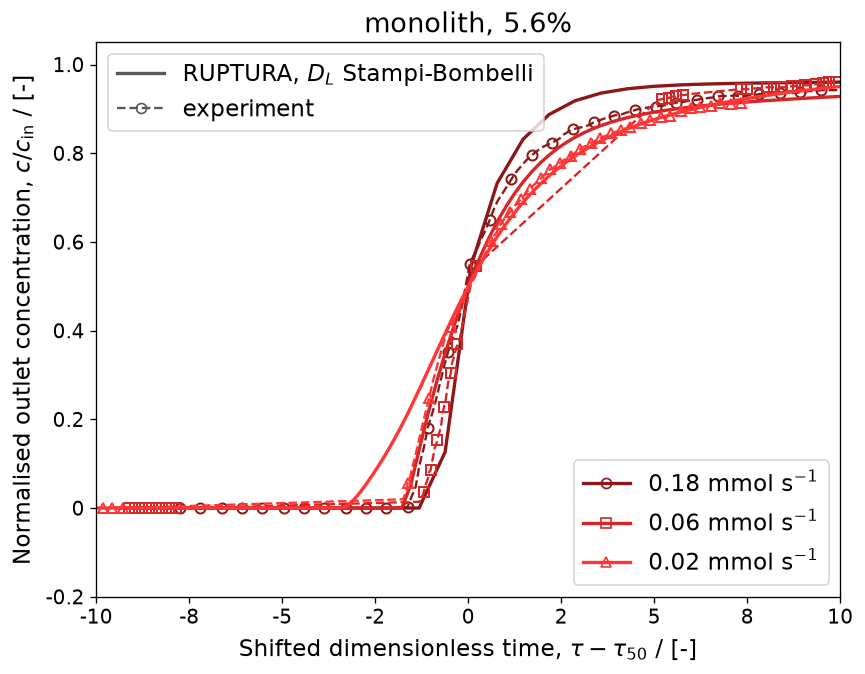

In [13]:
figure_5_panel("monolith_5.6pct", "tau", axis_limit=10.0, filename="figure_5e",
               title="monolith, 5.6%", dl_from="stampi_bombelli",
               legend_location="lower right")

### Figure 5f - monolith, 400 ppm, shifted by $\tau_{50}$

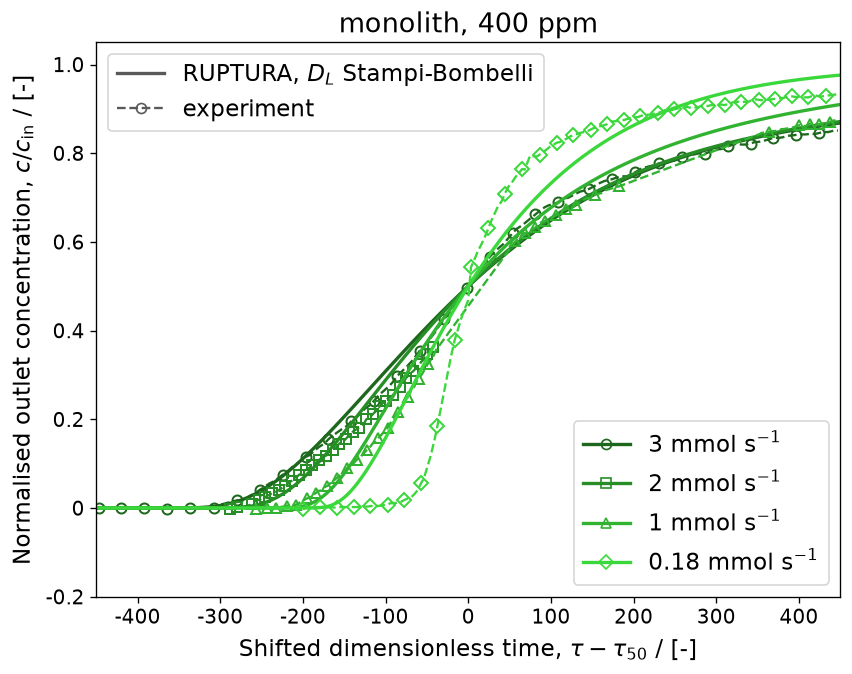

In [14]:
figure_5_panel("monolith_400ppm", "tau", axis_limit=450.0, filename="figure_5f",
               title="monolith, 400 ppm", dl_from="stampi_bombelli",
               legend_location="lower right", legend_columns=1)

## Mass-balance check

Every run is verified before it is plotted: the CO$_2$ held in the column (gas
plus adsorbed) plus the CO$_2$ that has left the outlet must equal the CO$_2$ fed
to the inlet.  The closure below is the ratio of the two, evaluated at the end of
each simulation.

In [15]:
import json


def check_mass_balance(case, model):
    # Ratio (stored + eluted) / fed at the end of the run; 1 means closure.
    with (ROOT / model / case / "simulation.json").open() as stream:
        settings = json.load(stream)
    void_fraction = settings["ColumnVoidFraction"]
    prefactor = settings["ParticleDensity"] * (1.0 - void_fraction) / void_fraction
    velocity = settings["ColumnEntranceVelocity"]

    data = np.loadtxt(ROOT / model / case / "component_1_CO2.data", comments="#")
    time_s = data[:, 1] * 60.0
    position = data[:, 2]
    loading = data[:, 6] + (data[:, 8] if data.shape[1] > 8 else 0.0)

    times, starts = np.unique(time_s, return_index=True)
    last = starts[-1]
    order = np.argsort(position[last:])
    z = position[last:][order]
    stored = (np.trapezoid(loading[last:][order], z) * prefactor
              + np.trapezoid(data[last:, 3][order], z))

    outlet = position > position.max() - 1.0e-9
    outlet_time = time_s[outlet]
    order = np.argsort(outlet_time)
    eluted = velocity * np.trapezoid(data[outlet, 3][order], outlet_time[order])

    fed = velocity * data[0, 3] * times[-1]
    return (stored + eluted) / fed


ALL_CASES = [case for panel in PANELS.values() for case in panel["cases"]]
balance = pd.DataFrame(
    {MODELS[model]["label"]: [check_mass_balance(case, model)
                              if available(case, model) else np.nan
                              for case in ALL_CASES]
     for model in MODELS},
    index=pd.Index(ALL_CASES, name="case"))
balance.columns.name = "closure, (stored + eluted) / fed / 1"
balance.style.format("{:.4f}")

"closure, (stored + eluted) / fed / 1","RUPTURA, $D_L$ Stampi-Bombelli","RUPTURA, $D_L$ literature"
case,,
packed_bed_400ppm_2mmol,nan,nan
packed_bed_5.6pct_2mmol,1.0000,1.0000
packed_bed_5.6pct_1mmol,1.0000,1.0000
packed_bed_5.6pct_0p5mmol,1.0000,1.0000
monolith_400ppm_3mmol,1.0000,1.0000
monolith_400ppm_2mmol,1.0000,1.0000
monolith_400ppm_1mmol,1.0000,1.0001
monolith_400ppm_0p18mmol,1.0000,1.0004
monolith_5.6pct_0p18mmol,1.0000,0.9999


## Table 6 - $q_{90}$, $t_{90}$ and $t_{50}$

$t_{50}$ and $t_{90}$ are the times at which the outlet reaches 50 % and 90 % of
the feed concentration; $q_{90}$ is the bed-average CO$_2$ loading at $t_{90}$.
Three sources are compared: the values printed in Table 6 of the paper, the same
quantities recovered from the digitised Figure 4 traces, and the RUPTURA
simulations.

In [16]:
TABLE_6_CASES = {
    "packed_bed_400ppm_2mmol": ("packed bed, 2 mmol s$^{-1}$", "400 ppm"),
    "packed_bed_5.6pct_2mmol": ("packed bed, 2 mmol s$^{-1}$", "5.6%"),
    "monolith_400ppm_0p18mmol": ("monolith, 0.18 mmol s$^{-1}$", "400 ppm"),
    "monolith_5.6pct_0p18mmol": ("monolith, 0.18 mmol s$^{-1}$", "5.6%"),
}

# Table 6 of the paper.
PAPER_TABLE_6 = {
    "packed_bed_400ppm_2mmol": dict(q90=0.44, t90=164255.0, t50=110389.0),
    "packed_bed_5.6pct_2mmol": dict(q90=0.71, t90=1960.0, t50=1214.0),
    "monolith_400ppm_0p18mmol": dict(q90=0.016, t90=14964.0, t50=11018.0),
    "monolith_5.6pct_0p18mmol": dict(q90=0.035, t90=258.0, t50=179.0),
}


def table_6_row(case):
    reference_time, reference_fraction = read_reference("figure4", case)
    if reference_time is None:
        digitised_50 = digitised_90 = np.nan
    else:
        digitised_50 = crossing(reference_time, reference_fraction, 0.5)
        digitised_90 = crossing(reference_time, reference_fraction, 0.9)

    paper = PAPER_TABLE_6[case]
    contactor, feed = TABLE_6_CASES[case]
    row = {
        "contactor": contactor,
        "feed": feed,
        "q90 paper / mmol g-1": paper["q90"],
        "t90 paper / s": paper["t90"],
        "t90 digitised / s": digitised_90,
        "t50 paper / s": paper["t50"],
        "t50 digitised / s": digitised_50,
    }

    for model in MODELS:
        tag = "lit." if model == "dl_from_literature" else "S-B"
        if not available(case, model):
            row[f"q90 RUPTURA {tag} / mmol g-1"] = np.nan
            row[f"t90 RUPTURA {tag} / s"] = np.nan
            row[f"t50 RUPTURA {tag} / s"] = np.nan
            continue
        time_s, fraction = read_ruptura(case, model)
        t50 = crossing(time_s, fraction, 0.5)
        t90 = crossing(time_s, fraction, 0.9)
        loading_time, loading = read_ruptura_loading(case, model)
        q90 = (float(np.interp(t90, loading_time, loading))
               if np.isfinite(t90) else np.nan)
        row[f"q90 RUPTURA {tag} / mmol g-1"] = q90
        row[f"t90 RUPTURA {tag} / s"] = t90
        row[f"t50 RUPTURA {tag} / s"] = t50
    return row


ORDER = ["q90 paper / mmol g-1", "q90 RUPTURA lit. / mmol g-1",
         "q90 RUPTURA S-B / mmol g-1",
         "t90 paper / s", "t90 digitised / s", "t90 RUPTURA lit. / s",
         "t90 RUPTURA S-B / s",
         "t50 paper / s", "t50 digitised / s", "t50 RUPTURA lit. / s",
         "t50 RUPTURA S-B / s"]

table_6 = pd.DataFrame([table_6_row(case) for case in TABLE_6_CASES])
table_6 = table_6.set_index(["contactor", "feed"]).T.loc[ORDER]
table_6.to_csv(ROOT / "figures" / "table_6.csv")
table_6.style.format("{:,.4g}")

## Notes on the agreement

* **Capacities and 50 % times.** The Toth isotherm of Table 1, the 3.5 % monolith
  scaling and the contactor masses reproduce $t_{50}$ across four orders of
  magnitude in time, from about 180 s on the monolith at 5.6 % to about
  110 000 s on the packed bed at 400 ppm, without a single adjustable
  equilibrium parameter.  This is the strongest part of the validation: it fixes
  the equilibrium description independently of any kinetics.

* **Monolith fronts.** The dual-kinetic split ($\eta$ = 0.75 with $k_1$ and $k_2$
  from Table 8) reproduces the sharp rise followed by the long tail that is
  characteristic of the monolith experiments, and the tail lengthens with
  decreasing velocity as in Figure 5f.

* **Packed-bed fronts at 5.6 %.** The heat released on adsorption reproduces the
  measured 43 $^\circ$C peak and the resulting loss of capacity.  At 2 mmol s$^{-1}$
  the fitted $D_L$ gives $t_{50}$ = 1448 s against the measured 1225 s and a
  mass-transfer zone of 62 % of the measured width; with the literature $D_L$ the
  zone is only 16-29 % of the measured width.

* **The two axial dispersion coefficients.** The fitted $D_L$ of Table 7 is up to
  three orders of magnitude above the literature correlation ($6.95u + 0.02
  \approx 1$ m$^2$ s$^{-1}$ on the packed bed at $u$ = 0.143 m s$^{-1}$, against
  $2.4 \times 10^{-4}$ m$^2$ s$^{-1}$): a column Peclet number $uL/D_L$ of about
  0.05 on the packed bed and 0.3-2 on the monolith.  Until 2026-11-03 RUPTURA held
  the inlet face at the feed concentration (Dirichlet inlet).  With such a $D_L$,
  dispersion across the inlet face then let in several times the feed, the outlet
  sat near the feed concentration almost from the start, and the fitted $D_L$
  looked unusable.  With the Danckwerts inlet (the default since 2026-11-03)
  exactly the feed enters, and the fitted $D_L$ reproduces the experiments:
  $t_{50}$ within -15 % to +24 % and 10-90 % widths of 60-133 % of the measured
  ones, against 11-72 % on the monolith with the literature correlations.  The
  authors attribute the large $D_L$ to bypassing and channelling (gas around and
  through the felts that hold the monolith; 3 mm rings in a 33.7 mm column); in a
  one-dimensional model it is a lumped parameter for that flow non-ideality.  The
  fitted $D_L$ is therefore the base model here, and `dl_from_literature` shows
  what the correlations alone give.

* **Occluded reference traces.** A few digitised traces are incomplete where the
  paper draws one curve on top of another - most visibly the flat temperature
  traces of Figure 4c, where the 1 mmol s$^{-1}$ curve is entirely hidden.  Those
  traces are simply absent from `reference_digitized/`.

## Two RUPTURA issues found while setting this case up

Both were hit here and are worth fixing upstream.

1. `computeConcentrationUpdateMatrixEnergyBalanceFinal` in
   `src/integrators/rk3_si.cpp` builds the banded matrix it hands to LAPACK's
   `dgbsv_` through `std::mdspan abS(ab.data(), 7, numberOfGridPoints + 1)`.
   Class template argument deduction gives that `std::layout_right`, but LAPACK
   band storage is column-major, so the matrix is transposed and every
   non-isothermal SIRK3 run aborts with *dgbsv failed*.  The sibling function
   `computeConcentrationUpdateMatrixFinal` spells the layout out explicitly; this
   one needs the same
   `std::mdspan<double, std::dextents<size_t, 2>, std::layout_left>`.

2. `updateStateRK` in `src/integrators/rk3_si.cpp` advances only the
   concentration and the physisorbed loading.  The chemisorbed loading, the pore
   and surface concentrations and the three temperatures are left at their
   initial values, while `computeBulkSpeciesSink` keeps subtracting their sinks
   from the gas phase.  A dual-kinetic run integrated with SIRK3 therefore
   destroys CO$_2$ at a constant rate and its outlet never reaches the feed
   concentration, with no warning.  Either those states should be advanced or
   SIRK3 should refuse a column that has chemisorption sites or an energy
   balance, the way it already refuses `General` chemisorption with surface-pore
   transport.  This is why the cases here use `RungeKutta3` and not SIRK3.

The mass-balance table above checks that stored plus eluted CO$_2$ equals the fed
amount in every run.  The explicit RK3 scheme, used here before ROS34PW2, needs a
step small enough that the concentration is never clamped at zero, because each
clamp creates CO$_2$.  At the 0.5 ms of the original set-up, the fitted-$D_L$
monolith at 0.02 mmol s$^{-1}$ breaks through 22 % early (TODO B-ITG-2).

## Figure 4b with a Figure 5d inset

The packed-bed, 5.6 % breakthrough curves of Figure 4b, with the $\tau$-shifted,
normalised curves of Figure 5d added as an inset so the front-steepness
comparison sits next to the curves it is shifted from.  Literature $D_L$ only.
This does not replace Figure 4b or Figure 5d above; it is an additional,
combined view.

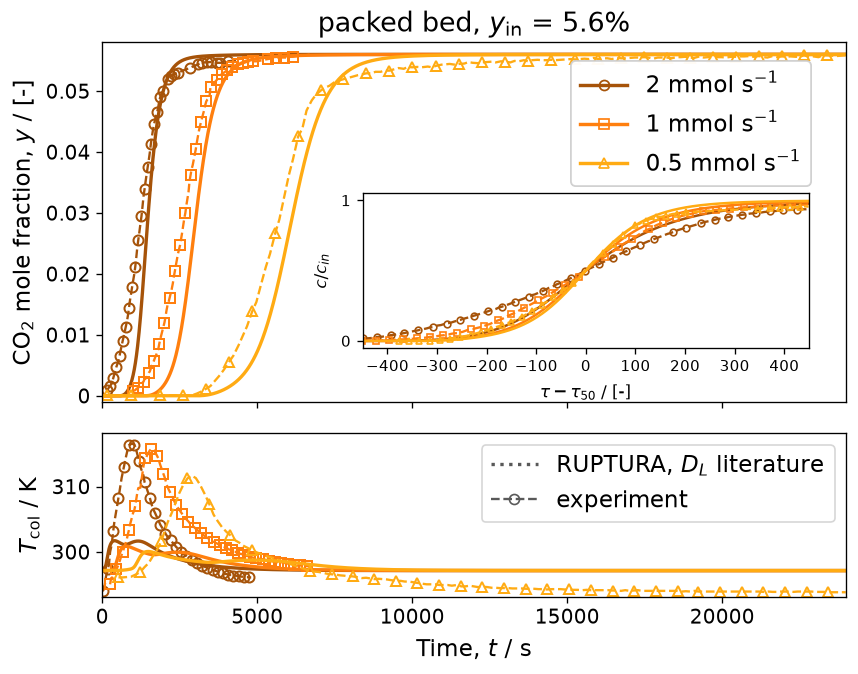

In [17]:
key = "packed_bed_5.6pct"
panel = PANELS[key]
styles = panel_styles(key)
model = "dl_from_stampibombelli"
length = COLUMN_LENGTH[contactor_of(panel["cases"][0])]

figure, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0], "hspace": 0.12})

for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    top.plot(time_s, fraction * 0.056, color=colour,
             linestyle=style["linestyle"], linewidth=style["width"])

    temperature_time, temperature = read_ruptura_temperature(
        case, panel["thermocouple"], model)
    bottom.plot(temperature_time, temperature, color=colour,
                linestyle=style["linestyle"], linewidth=style["width"])

    reference_time, reference_fraction = read_reference("figure4", case)
    if reference_time is not None:
        plot_reference(top, reference_time, reference_fraction * 0.056, colour, marker)

    reference_time, reference_temperature = read_reference(
        "figure4_temperature", case)
    if reference_time is not None:
        plot_reference(bottom, reference_time, reference_temperature + 273.15,
                       colour, marker)

top.set(xlim=(0.0, 24000.0), ylim=(-1e-3, 5.8e-2),
        ylabel=r"CO$_2$ mole fraction, $y$ / [-]",
        title=f"{panel['contactor']}, {panel['feed']}")
format_axis_ticks(top, "y")
top.tick_params(labelbottom=False)
flow_handles = flow_legend(top, styles, loc=(0.63, 0.6))
top.add_artist(flow_handles)
line_style_legend(bottom, "literature", loc="upper right", ncol=1)

bottom.set(xlim=(0.0, 24000.0), ylim=(293.15, 318.15),
           xlabel=r"Time, $t$ / s", ylabel=r"$T_{\mathrm{col}}$ / K")
format_axis_ticks(bottom, "x")

# Inset: Figure 5d content (tau-shifted, normalised concentration), literature
# D_L only, positioned lower-left where the saturated curves leave it clear of
# the flow-rate legend above.
inset = top.inset_axes([0.35, 0.15, 0.60, 0.43])
for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    half = crossing(time_s, fraction, 0.5)
    velocity = np.loadtxt(ROOT / model / case / "column.data", comments="#")[0, 3]
    abscissa = (time_s - half) * velocity / length
    inset.plot(abscissa, fraction, color=colour,
               linestyle=style["linestyle"], linewidth=1.5)

    reference_x, reference_y = read_reference("figure5_tau", case)
    if reference_x is not None:
        # plot_reference(inset, reference_x, reference_y, colour, marker)

        inset.plot(reference_x, reference_y, linestyle="--", linewidth=1.4, color=colour,
                     marker=marker, markevery=marker_stride(len(reference_x)),
                     markerfacecolor="none", markeredgecolor=colour,
                     markersize=4)

inset.set_xlim(-450.0, 450.0)
inset.set_ylim(-0.05, 1.05)
inset.set_yticks([0, 1])
inset.set_ylabel(r"$c/c_{in}$", fontsize=10)
inset.set_xlabel(r"$\tau - \tau_{50}$ / [-]", fontsize=10)
inset.tick_params(labelsize=9)

figure.savefig(FIGURES / "figure_4b_inset_5d.pdf", bbox_inches="tight")
figure.savefig(FIGURES / "figure_4b_inset_5d.png", bbox_inches="tight")
plt.show()

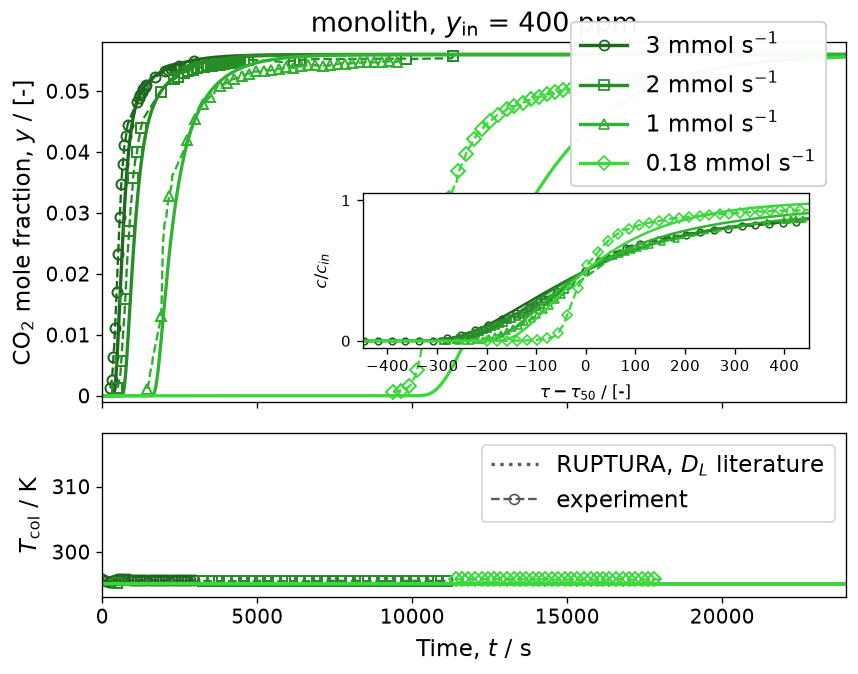

In [18]:
key = "monolith_400ppm"
panel = PANELS[key]
styles = panel_styles(key)
model = "dl_from_stampibombelli"
length = COLUMN_LENGTH[contactor_of(panel["cases"][0])]

figure, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0], "hspace": 0.12})

for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    top.plot(time_s, fraction * 0.056, color=colour,
             linestyle=style["linestyle"], linewidth=style["width"])

    temperature_time, temperature = read_ruptura_temperature(
        case, panel["thermocouple"], model)
    bottom.plot(temperature_time, temperature, color=colour,
                linestyle=style["linestyle"], linewidth=style["width"])

    reference_time, reference_fraction = read_reference("figure4", case)
    if reference_time is not None:
        plot_reference(top, reference_time, reference_fraction * 0.056, colour, marker)

    reference_time, reference_temperature = read_reference(
        "figure4_temperature", case)
    if reference_time is not None:
        plot_reference(bottom, reference_time, reference_temperature + 273.15,
                       colour, marker)

top.set(xlim=(0.0, 24000.0), ylim=(-1e-3, 5.8e-2),
        ylabel=r"CO$_2$ mole fraction, $y$ / [-]",
        title=f"{panel['contactor']}, {panel['feed']}")
format_axis_ticks(top, "y")
top.tick_params(labelbottom=False)
flow_handles = flow_legend(top, styles, loc=(0.63, 0.6))
top.add_artist(flow_handles)
line_style_legend(bottom, "literature", loc="upper right", ncol=1)

bottom.set(xlim=(0.0, 24000.0), ylim=(293.15, 318.15),
           xlabel=r"Time, $t$ / s", ylabel=r"$T_{\mathrm{col}}$ / K")
format_axis_ticks(bottom, "x")

# Inset: Figure 5d content (tau-shifted, normalised concentration), literature
# D_L only, positioned lower-left where the saturated curves leave it clear of
# the flow-rate legend above.
inset = top.inset_axes([0.35, 0.15, 0.60, 0.43])
for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    half = crossing(time_s, fraction, 0.5)
    velocity = np.loadtxt(ROOT / model / case / "column.data", comments="#")[0, 3]
    abscissa = (time_s - half) * velocity / length
    inset.plot(abscissa, fraction, color=colour,
               linestyle=style["linestyle"], linewidth=1.5)

    reference_x, reference_y = read_reference("figure5_tau", case)
    if reference_x is not None:
        # plot_reference(inset, reference_x, reference_y, colour, marker)

        inset.plot(reference_x, reference_y, linestyle="--", linewidth=1.4, color=colour,
                     marker=marker, markevery=marker_stride(len(reference_x)),
                     markerfacecolor="none", markeredgecolor=colour,
                     markersize=4)

inset.set_xlim(-450.0, 450.0)
inset.set_ylim(-0.05, 1.05)
inset.set_yticks([0, 1])
inset.set_ylabel(r"$c/c_{in}$", fontsize=10)
inset.set_xlabel(r"$\tau - \tau_{50}$ / [-]", fontsize=10)
inset.tick_params(labelsize=9)

figure.savefig(FIGURES / "figure_4b_inset_5d.pdf", bbox_inches="tight")
figure.savefig(FIGURES / "figure_4b_inset_5d.png", bbox_inches="tight")
plt.show()

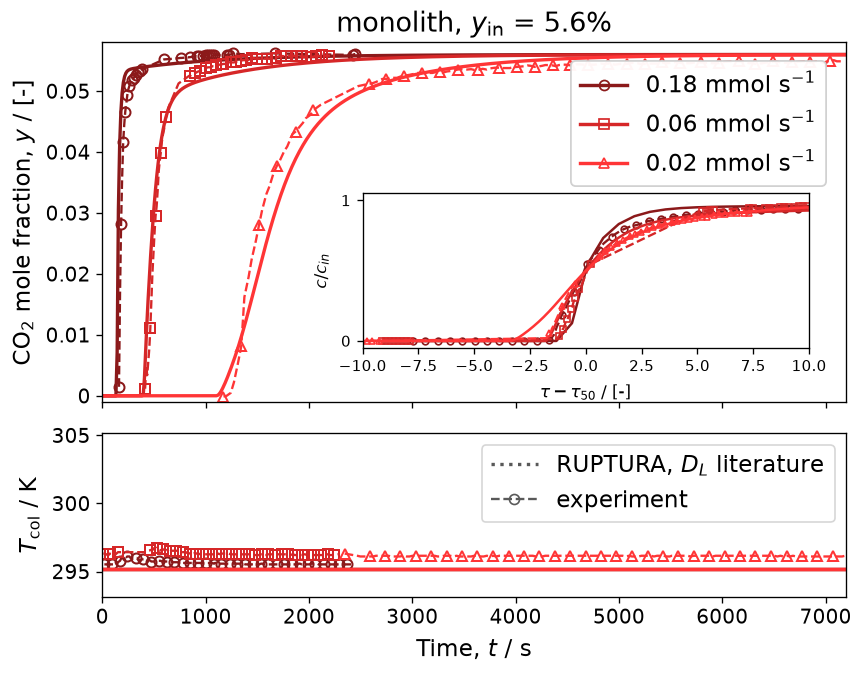

In [19]:
key = "monolith_5.6pct"
panel = PANELS[key]
styles = panel_styles(key)
model = "dl_from_stampibombelli"
length = COLUMN_LENGTH[contactor_of(panel["cases"][0])]

figure, (top, bottom) = plt.subplots(
    2, 1, figsize=(8, 6), sharex=True,
    gridspec_kw={"height_ratios": [2.2, 1.0], "hspace": 0.12})

for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    top.plot(time_s, fraction * 0.056, color=colour,
             linestyle=style["linestyle"], linewidth=style["width"])

    temperature_time, temperature = read_ruptura_temperature(
        case, panel["thermocouple"], model)
    bottom.plot(temperature_time, temperature, color=colour,
                linestyle=style["linestyle"], linewidth=style["width"])

    reference_time, reference_fraction = read_reference("figure4", case)
    if reference_time is not None:
        plot_reference(top, reference_time, reference_fraction * 0.056, colour, marker)

    reference_time, reference_temperature = read_reference(
        "figure4_temperature", case)
    if reference_time is not None:
        plot_reference(bottom, reference_time, reference_temperature + 273.15,
                       colour, marker)

top.set(xlim=(0.0, 7200.0), ylim=(-1e-3, 5.8e-2),
        ylabel=r"CO$_2$ mole fraction, $y$ / [-]",
        title=f"{panel['contactor']}, {panel['feed']}")
format_axis_ticks(top, "y")
top.tick_params(labelbottom=False)
flow_handles = flow_legend(top, styles, loc=(0.63, 0.6))
top.add_artist(flow_handles)
line_style_legend(bottom, "literature", loc="upper right", ncol=1)

bottom.set(xlim=(0.0, 7200.0), ylim=(293.15, 305.15),
           xlabel=r"Time, $t$ / s", ylabel=r"$T_{\mathrm{col}}$ / K")
format_axis_ticks(bottom, "x")

# Inset: Figure 5d content (tau-shifted, normalised concentration), literature
# D_L only, positioned lower-left where the saturated curves leave it clear of
# the flow-rate legend above.
inset = top.inset_axes([0.35, 0.15, 0.60, 0.43])
for case, (colour, marker) in styles.items():
    if not available(case, model):
        continue
    style = MODELS[model]
    time_s, fraction = read_ruptura(case, model)
    half = crossing(time_s, fraction, 0.5)
    velocity = np.loadtxt(ROOT / model / case / "column.data", comments="#")[0, 3]
    abscissa = (time_s - half) * velocity / length
    inset.plot(abscissa, fraction, color=colour,
               linestyle=style["linestyle"], linewidth=1.5)

    reference_x, reference_y = read_reference("figure5_tau", case)
    if reference_x is not None:
        # plot_reference(inset, reference_x, reference_y, colour, marker)

        inset.plot(reference_x, reference_y, linestyle="--", linewidth=1.4, color=colour,
                     marker=marker, markevery=marker_stride(len(reference_x)),
                     markerfacecolor="none", markeredgecolor=colour,
                     markersize=4)

inset.set_xlim(-10.0, 10.0)
inset.set_ylim(-0.05, 1.05)
inset.set_yticks([0, 1])
inset.set_ylabel(r"$c/c_{in}$", fontsize=10)
inset.set_xlabel(r"$\tau - \tau_{50}$ / [-]", fontsize=10)
inset.tick_params(labelsize=9)

figure.savefig(FIGURES / "figure_4b_inset_5d.pdf", bbox_inches="tight")
figure.savefig(FIGURES / "figure_4b_inset_5d.png", bbox_inches="tight")
plt.show()